## Problema 2 — Rede MLP para Detecção de Ataques em Redes de Computadores

Classificação de conexões de redes como normais ou ataques utilizando o dataset NSL-KDD

### 1. Importação das bibliotecas

In [1]:
from pathlib import Path
from copy import deepcopy

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Versão do PyTorch:", torch.__version__)
print("Dispositivo utilizado:", device)

Versão do PyTorch: 2.15.0+cpu
Dispositivo utilizado: cpu


### 2. Carregamento e análise exploratória do dataset

In [3]:
col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised", 
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count", 
    "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", 
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate", 
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack_type", "difficulty_level"
]

print("Quantidade de colunas:", len(col_names))

Quantidade de colunas: 43


In [4]:
project_dir = Path.cwd()

if project_dir.name != "projeto_02_mlp":
    project_dir = project_dir / "projeto_02_mlp"

data_dir = project_dir / "data"
figures_dir = project_dir / "figuras"

figures_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    data_dir / "KDDTrain+.txt",
    header=None,
    names=col_names
)

test_df = pd.read_csv(
    data_dir / "KDDTest+.txt",
    header=None,
    names=col_names
)

print("Dimensões do conjunto de treino:", train_df.shape)
print("Dimensões do conjunto de teste:", test_df.shape)

display(train_df.head())

Dimensões do conjunto de treino: (125973, 43)
Dimensões do conjunto de teste: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
print("Valores ausentes no treino:")
print(train_df.isnull().sum().sum())

print("\nValores ausentes no teste:")
print(test_df.isnull().sum().sum())

print("\nTipos de dados:")
print(train_df.dtypes)

print("\nDistribuição dos tipos de conexão:")
print(train_df["attack_type"].value_counts())

Valores ausentes no treino:
0

Valores ausentes no teste:
0

Tipos de dados:
duration                         int64
protocol_type                      str
service                            str
flag                               str
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                 

### 3. Pré-processamento dos dados

In [6]:
train_df = train_df.drop(columns=["difficulty_level"])
test_df = test_df.drop(columns=["difficulty_level"])

print("Dimensões do treino:", train_df.shape)
print("Dimensões do teste:", test_df.shape)

Dimensões do treino: (125973, 42)
Dimensões do teste: (22544, 42)


In [7]:
train_df["attack_type"] = (
    train_df["attack_type"] != "normal"
).astype(int)

test_df["attack_type"] = (
    test_df["attack_type"] != "normal"
).astype(int)

print("Distribuição das classes no treino:")
print(train_df["attack_type"].value_counts().sort_index())

print("\nDistribuição das classes no teste:")
print(test_df["attack_type"].value_counts().sort_index())

Distribuição das classes no treino:
attack_type
0    67343
1    58630
Name: count, dtype: int64

Distribuição das classes no teste:
attack_type
0     9711
1    12833
Name: count, dtype: int64


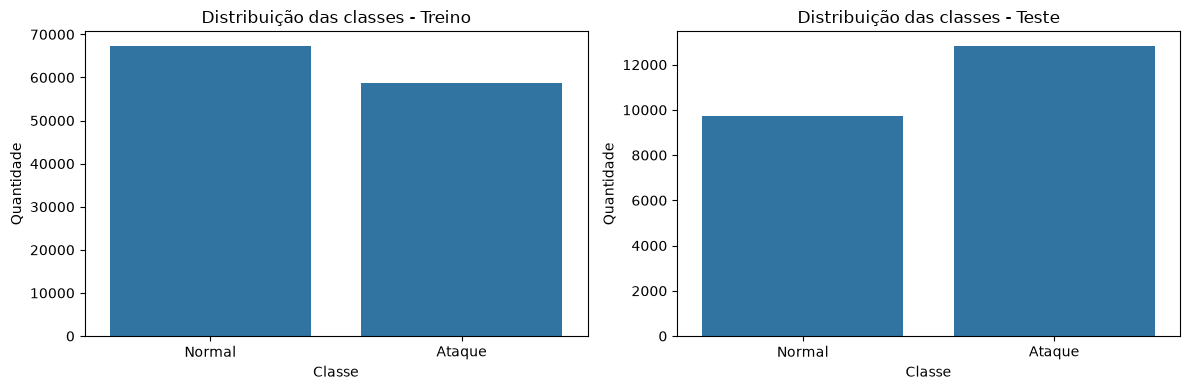

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=train_df,
    x="attack_type",
    ax=axes[0]
)

axes[0].set_title("Distribuição das classes - Treino")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Quantidade")
axes[0].set_xticks([0, 1], ["Normal", "Ataque"])

sns.countplot(
    data=test_df,
    x="attack_type",
    ax=axes[1]
)

axes[1].set_title("Distribuição das classes - Teste")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Quantidade")
axes[1].set_xticks([0, 1], ["Normal", "Ataque"])

plt.tight_layout()

plt.savefig(
    figures_dir / "01_distribuicao_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
X = train_df.drop(columns=["attack_type"])
y = train_df["attack_type"]

X_test = test_df.drop(columns=["attack_type"])
y_test = test_df["attack_type"]

print("Atributos de entrada:", X.shape[1])

Atributos de entrada: 41


In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (100778, 41)
Validação: (25195, 41)
Teste: (22544, 41)


In [11]:
categorical_cols = [
    "protocol_type",
    "service",
    "flag"
]

numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Atributos categóricos:", len(categorical_cols))
print("Atributos numéricos:", len(numerical_cols))

Atributos categóricos: 3
Atributos numéricos: 38


In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_cols
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Treino:", X_train_processed.shape)
print("Validação:", X_val_processed.shape)
print("Teste:", X_test_processed.shape)

Treino: (100778, 121)
Validação: (25195, 121)
Teste: (22544, 121)


In [13]:
n_numeric = len(numerical_cols)

numeric_train = X_train_processed[:, :n_numeric]

numeric_stats = pd.DataFrame({
    "Atributo": numerical_cols,
    "Média": numeric_train.mean(axis=0),
    "Desvio padrão": numeric_train.std(axis=0)
})

display(numeric_stats.round(6))

,Atributo,Média,Desvio padrão
0,duration,-0.0,1.0
1,src_bytes,0.0,1.0
2,dst_bytes,-0.0,1.0
3,land,-0.0,1.0
4,wrong_fragment,0.0,1.0
5,urgent,0.0,1.0
6,hot,0.0,1.0
7,num_failed_logins,0.0,1.0
8,logged_in,-0.0,1.0
9,num_compromised,-0.0,1.0
